# Machine Learning Model for Loan Approval
A Data-Driven Approach to Loan Risk Assessment and Decision Making

**Company**: FinTech Innovations

**Project**: Summative Lab – Machine Learning

**Methodology**: CRISP-DM

## Overview
This project aims to develop a machine learning model to support loan approval decisions at FinTech Innovations. The current process relies heavily on manual assessments, which can lead to inconsistent decisions and delays. Using historical loan application data, the project will explore applicant characteristics, develop and compare predictive models, and evaluate their performance against business objectives. The analysis will follow the CRISP-DM framework, covering business understanding, data exploration, preparation, modeling, and evaluation. Particular attention will be given to the financial impact of incorrect loan decisions, model interpretability, and potential bias.



## Business Understanding

### Question 1: Business Context and Problem Definition

#### 1.1 Current Loan Approval Process and Its Limitations

FinTech Innovations currently relies on loan officers to manually review applications and assess applicants' creditworthiness. This process presents several challenges:

- **Inconsistent decisions:** Different loan officers may assess similar applications differently.
- **Slow processing:** Manual reviews increase the time taken to approve or reject applications.
- **Human bias:** Subjective judgments may influence decisions and disadvantage some applicants.
- **Financial losses:** Incorrect decisions may result in approving high-risk applicants or rejecting creditworthy customers.

The proposed machine learning model aims to support more consistent, timely, and data-driven loan decisions.

#### 1.2 Key Stakeholders and Their Needs

The main stakeholders include:

- **Loan Officers:** Need reliable risk predictions to support loan assessments and reduce manual workload.
- **Management:** Needs to reduce financial losses, improve decision-making, and maintain profitability.
- **Risk Analytics Team:** Needs an accurate, interpretable model that can be monitored and evaluated.
- **Loan Applicants:** Expect fair, consistent, and timely decisions.
- **Regulators and Compliance Teams:** Require transparent decisions that comply with lending regulations and minimise unfair discrimination.

#### 1.3 Financial Implications of Model Errors

The business faces two major types of prediction errors:

**False Approval:** Approving an applicant who subsequently defaults.

- Average financial loss: $50,000 per loan.
- This increases credit losses and exposes the business to financial risk.

**False Denial:** Rejecting an applicant who would have repaid the loan.

- Average lost profit: $8,000 per loan.
- This reduces potential revenue and may affect customer satisfaction.

For example, if the model incorrectly approves 10 applicants who default and rejects 10 creditworthy applicants:

- Cost of false approvals = 10 × $50,000 = $500,000
- Cost of false denials = 10 × $8,000 = $80,000
- **Total estimated business cost = $580,000**

Since a false approval is 6.25 times more costly than a false denial, the model should place greater emphasis on identifying high-risk applicants while avoiding unnecessary rejection of creditworthy customers.

#### 1.4 Choice of Modeling Approach

A **classification approach** is recommended because the business needs to support loan approval decisions using predictions about applicant risk.

Classification models can assign applicants to categories such as lower-risk and higher-risk, allowing loan officers to make informed decisions.

The dataset contains a `LoanApproved` variable, which can serve as a binary target for predicting historical approval decisions. However, approval status does not necessarily indicate whether an applicant subsequently defaulted. Therefore, the available target variables must be examined before deciding whether the model can directly predict default risk.

Classification is preferred over regression for the initial analysis because:

- The available `LoanApproved` target represents a binary outcome.
- Classification supports evaluation using precision, recall, F1-score, and confusion matrices.
- Predicted probabilities can support risk-based decision thresholds.
- Classification results can be linked to the financial consequences of incorrect decisions.

A regression approach using `RiskScore` could also support risk assessment, but it would require different evaluation metrics and a clear understanding of how the risk score was calculated.

**Recommended Approach:** Begin with binary classification using the available approval outcome, while recognising that predicting historical approvals is not the same as predicting actual defaults. The model's business limitations will be documented during evaluation.

### Question 2: Modeling Goals and Success Criteria

#### 2.1 Modeling Goals

The primary goal is to develop a classification model that can predict loan approval outcomes and support consistent, data-driven lending decisions.

The specific objectives are to:

- Predict whether a loan application is likely to be approved or denied based on applicant characteristics.
- Compare different machine learning algorithms to identify the best-performing model.
- Minimise prediction errors, particularly those that could expose the business to financial losses.
- Develop an interpretable model that loan officers can use to support their decisions.
- Evaluate the model's ability to make accurate predictions on unseen data.

Since the dataset contains historical approval decisions rather than confirmed default outcomes, the model will initially predict approval status. Its ability to estimate actual default risk cannot be established without suitable repayment outcome data.

#### 2.2 Selection of Evaluation Metrics

The following metrics will be used to evaluate model performance.

**1. Precision**

Precision measures the proportion of predicted approvals that were actually approved in the historical data.

Precision = TP / (TP + FP)

High precision is desirable because it reduces the number of applications incorrectly classified as approved.

**2. Recall**

Recall measures the proportion of historically approved applications that the model correctly identifies.

Recall = TP / (TP + FN)

High recall helps reduce the number of potentially creditworthy applicants incorrectly classified as denied.

**3. F1-Score**

The F1-score combines precision and recall into a single measure.

F1-Score = 2 × (Precision × Recall) / (Precision + Recall)

This metric is useful because the dataset has an imbalanced target distribution, with fewer approved applications than denied applications.

**4. ROC-AUC**

ROC-AUC measures how well the model distinguishes between approved and denied applications across different classification thresholds.

A higher ROC-AUC indicates better discrimination between the two classes.

**5. Business Cost Metric**

The assignment provides the following financial consequences:

- False approval resulting in default: $50,000
- False denial of a creditworthy applicant: $8,000

The proposed business cost formula is:

**Total Business Cost = (Number of False Approvals × $50,000) + (Number of False Denials × $8,000)**

This metric will help compare models based on their potential financial impact rather than predictive performance alone.

The cost calculation will only represent actual lending risk if the target variable identifies creditworthy and defaulting applicants. Since `LoanApproved` records historical decisions, applying these costs to its classification errors would be illustrative rather than a validated estimate of financial losses.

#### 2.3 Baseline Performance and Success Criteria

A baseline model will be established to provide a reference point for evaluating more advanced algorithms.

The initial baseline will use a Dummy Classifier that predicts the majority class.

Based on the observed dataset distribution:

- Denied applications: 76.1%
- Approved applications: 23.9%
- Majority-class baseline accuracy: 76.1%

A model that always predicts denial would achieve 76.1% accuracy but would fail to identify any approved applications.

The following preliminary success criteria will guide model development:

| Metric | Initial Target |
|---|---|
| Accuracy | Above 76.1% baseline |
| Precision | At least 80% |
| Recall | At least 75% |
| F1-Score | At least 0.75 |
| ROC-AUC | At least 0.85 |
| Business Cost | Lower than the baseline under a valid cost evaluation |

These are proposed targets rather than guaranteed outcomes. Their suitability will be assessed after baseline modeling and cross-validation.

#### 2.4 Justification of the Selected Metrics

Accuracy alone is insufficient because the dataset contains more denied applications than approved applications.

Precision and recall will help assess the trade-off between incorrect approvals and incorrect denials. The F1-score provides a balanced measure, while ROC-AUC evaluates the model's ability to distinguish between the two classes.

The business cost metric is particularly relevant because the financial consequences of incorrect lending decisions are unequal. A false approval that leads to default costs substantially more than a false denial.

For this reason, model selection will consider both predictive performance and the financial consequences of errors, while recognising the limitations of the available target variable.

**Success will be achieved when the selected model consistently outperforms the baseline on appropriate evaluation metrics, demonstrates good performance on unseen data, and provides interpretable predictions that can support loan officers' decisions.**


## Data Understanding
Questions 3 and 4: Exploratory Data Analysis and Feature Understanding

This section examines the dataset's structure, feature distributions, loan approval patterns and relationships between applicant characteristics.

The analysis includes descriptive statistics, visualizations, correlation analysis, missing-value assessment and identification of potential outliers.

Features are also examined to determine their data types, preprocessing requirements and potential data quality concerns.

The findings inform the feature selection and preprocessing decisions applied during model development.

In [1]:
# Imports

# Import libraries for data analysis and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)

# Visualization settings
sns.set_theme(style='whitegrid')

print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:
# EDA Code Here - Create New Cells As Needed

# Load the dataset
df = pd.read_csv("financial_loan_data.csv")

# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Display the first five rows
display(df.head())

# Examine column names, data types and missing values
print("\nDataset Information:")
df.info()


Dataset Shape: (20000, 35)


,Age,AnnualIncome,CreditScore,EmploymentStatus,EducationLevel,Experience,LoanAmount,LoanDuration,MaritalStatus,NumberOfDependents,HomeOwnershipStatus,MonthlyDebtPayments,CreditCardUtilizationRate,NumberOfOpenCreditLines,NumberOfCreditInquiries,DebtToIncomeRatio,BankruptcyHistory,LoanPurpose,PreviousLoanDefaults,PaymentHistory,LengthOfCreditHistory,SavingsAccountBalance,CheckingAccountBalance,TotalAssets,TotalLiabilities,MonthlyIncome,UtilityBillsPaymentHistory,JobTenure,NetWorth,BaseInterestRate,InterestRate,MonthlyLoanPayment,TotalDebtToIncomeRatio,LoanApproved,RiskScore
0,45,"$39,948.00",617,Employed,Master,22,13152,48,Married,2,Own,183,0.354418,1,2,0.358336,No,Home,0,29,9,7632.0,1202,146111,19183,3329.000000,0.724972,11,126928,0.199652,0.227590,419.805992,0.181077,0,49.0
1,38,"$39,709.00",628,Employed,Associate,15,26045,48,Single,1,Mortgage,496,0.087827,5,3,0.330274,No,Debt Consolidation,0,21,9,4627.0,3460,53204,9595,3309.083333,0.935132,3,43609,0.207045,0.201077,794.054238,0.389852,0,52.0
2,47,"$40,724.00",570,Employed,Bachelor,26,17627,36,NaN,2,Rent,902,0.137414,2,0,0.244729,No,Education,0,20,22,886.0,895,25176,128874,3393.666667,0.872241,6,5205,0.217627,0.212548,666.406688,0.462157,0,52.0
3,58,"$69,084.00",545,Employed,High School,34,37898,96,Single,1,Mortgage,755,0.267587,2,1,0.436244,No,Home,0,27,10,1675.0,1217,104822,5370,5757.000000,0.896155,5,99452,0.300398,0.300911,1047.506980,0.313098,0,54.0
4,37,"$103,264.00",594,Employed,Associate,17,9184,36,Married,1,Mortgage,274,0.320535,0,0,0.078884,No,Debt Consolidation,0,26,27,1555.0,4981,244305,17286,8605.333333,0.941369,5,227019,0.197184,0.175990,330.179140,0.070210,1,36.0



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 35 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         20000 non-null  int64  
 1   AnnualIncome                20000 non-null  object 
 2   CreditScore                 20000 non-null  int64  
 3   EmploymentStatus            20000 non-null  object 
 4   EducationLevel              19099 non-null  object 
 5   Experience                  20000 non-null  int64  
 6   LoanAmount                  20000 non-null  int64  
 7   LoanDuration                20000 non-null  int64  
 8   MaritalStatus               18669 non-null  object 
 9   NumberOfDependents          20000 non-null  int64  
 10  HomeOwnershipStatus         20000 non-null  object 
 11  MonthlyDebtPayments         20000 non-null  int64  
 12  CreditCardUtilizationRate   20000 non-null  float64
 13  NumberOfO

In [3]:

# Check duplicate records
print("Duplicate Records:", df.duplicated().sum())

# Examine loan approval distribution
print("\nLoan Approval Counts:")
print(df["LoanApproved"].value_counts())

print("\nLoan Approval Percentages:")
print(df["LoanApproved"].value_counts(normalize=True) * 100)


Duplicate Records: 0

Loan Approval Counts:
LoanApproved
0    15220
1     4780
Name: count, dtype: int64

Loan Approval Percentages:
LoanApproved
0    76.1
1    23.9
Name: proportion, dtype: float64


In [4]:

# Summary statistics for numerical variables
print("Numerical Feature Summary:")
display(df.describe().T.round(2))

# Summary of categorical variables
print("\nCategorical Feature Summary:")
display(df.describe(include=["object"]).T)


Numerical Feature Summary:


,count,mean,std,min,25%,50%,75%,max
Age,20000.0,39.75,11.62,18.00,32.00,40.00,48.00,80.00
CreditScore,20000.0,571.61,51.00,343.00,540.00,578.00,609.00,712.00
Experience,20000.0,17.52,11.32,0.00,9.00,17.00,25.00,61.00
LoanAmount,20000.0,24882.87,13427.42,3674.00,15575.00,21914.50,30835.00,184732.00
LoanDuration,20000.0,54.06,24.66,12.00,36.00,48.00,72.00,120.00
NumberOfDependents,20000.0,1.52,1.39,0.00,0.00,1.00,2.00,5.00
MonthlyDebtPayments,20000.0,454.29,240.51,50.00,286.00,402.00,564.00,2919.00
CreditCardUtilizationRate,20000.0,0.29,0.16,0.00,0.16,0.27,0.39,0.92
NumberOfOpenCreditLines,20000.0,3.02,1.74,0.00,2.00,3.00,4.00,13.00
NumberOfCreditInquiries,20000.0,0.99,0.99,0.00,0.00,1.00,2.00,7.00



Categorical Feature Summary:


,count,unique,top,freq
AnnualIncome,20000,17516,"$15,000.00",584
EmploymentStatus,20000,3,Employed,17036
EducationLevel,19099,5,Bachelor,5804
MaritalStatus,18669,4,Married,9370
HomeOwnershipStatus,20000,4,Mortgage,7939
BankruptcyHistory,20000,2,No,18952
LoanPurpose,20000,5,Home,5925


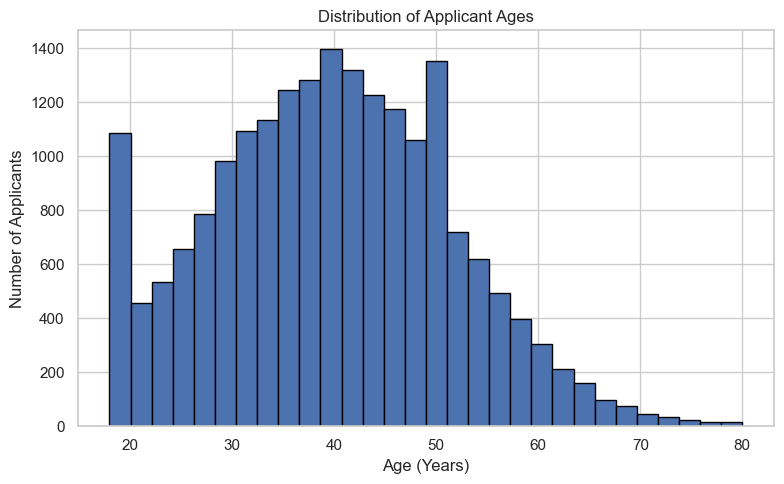

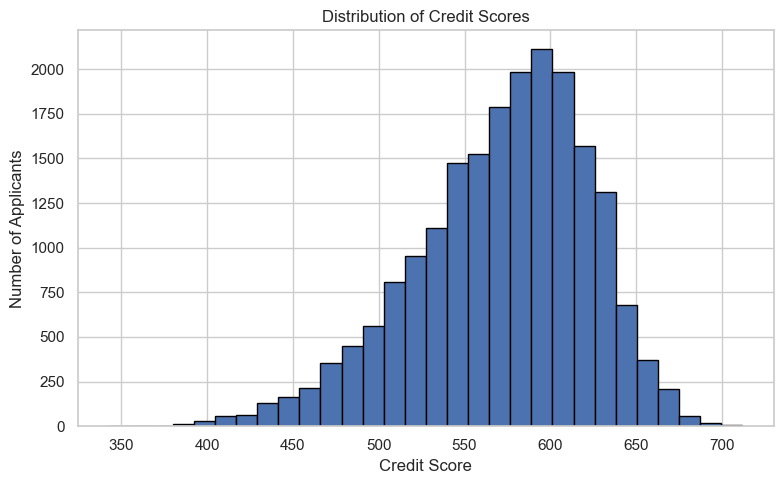

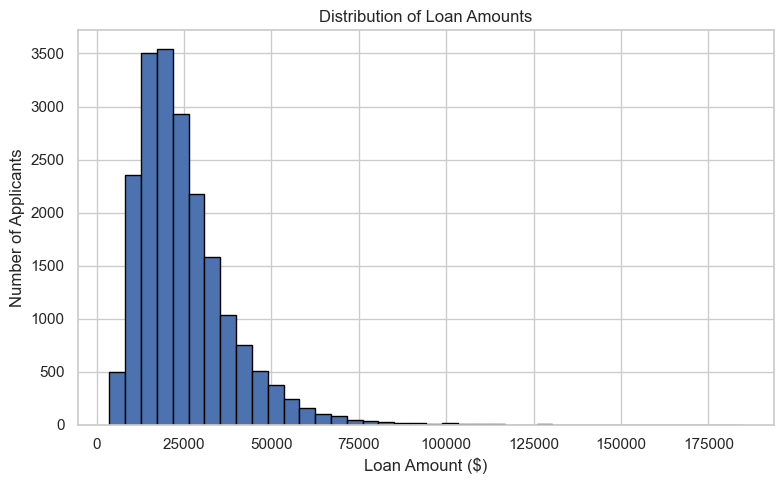

In [5]:

# Visualisation 1: Distribution of applicant ages
plt.figure(figsize=(8, 5))
plt.hist(df["Age"], bins=30, edgecolor="black")
plt.title("Distribution of Applicant Ages")
plt.xlabel("Age (Years)")
plt.ylabel("Number of Applicants")
plt.tight_layout()
plt.show()

# Visualisation 2: Distribution of credit scores
plt.figure(figsize=(8, 5))
plt.hist(df["CreditScore"], bins=30, edgecolor="black")
plt.title("Distribution of Credit Scores")
plt.xlabel("Credit Score")
plt.ylabel("Number of Applicants")
plt.tight_layout()
plt.show()

# Visualisation 3: Distribution of loan amounts
plt.figure(figsize=(8, 5))
plt.hist(df["LoanAmount"], bins=40, edgecolor="black")
plt.title("Distribution of Loan Amounts")
plt.xlabel("Loan Amount ($)")
plt.ylabel("Number of Applicants")
plt.tight_layout()
plt.show()


### Interpretation of Numerical Feature Distributions

**1. Distribution of Applicant Ages**

- Most loan applicants are aged between 30 and 50 years, with an average age of 39.75 years.
- The distribution is slightly right-skewed, with fewer applicants in the older age groups.
- There is a noticeable concentration of applicants aged 18–20 that may warrant further investigation.
- Age may be associated with loan approval decisions, although this relationship requires further analysis.

**2. Distribution of Credit Scores**

- Credit scores are concentrated between approximately 500 and 650, with an average of 571.61.
- The distribution is negatively skewed, with a longer tail towards lower credit scores.
- Relatively few applicants have scores below 450 or above 680.
- Credit scores may help explain differences in loan approval outcomes.

**3. Distribution of Loan Amounts**

- Loan amounts are positively skewed, with most applications concentrated between approximately $10,000 and $35,000.
- The average requested loan amount is $24,882.87.
- A small number of applicants request substantially larger loans, with the maximum reaching $184,732.
- These extreme values should be investigated during data preparation rather than automatically removed.

**Overall Observation**

The numerical variables show different distribution patterns. Age and credit scores have moderate concentrations around their central values, while loan amounts exhibit substantial right-skewness. These findings suggest that outlier assessment and appropriate preprocessing will be necessary before model development.

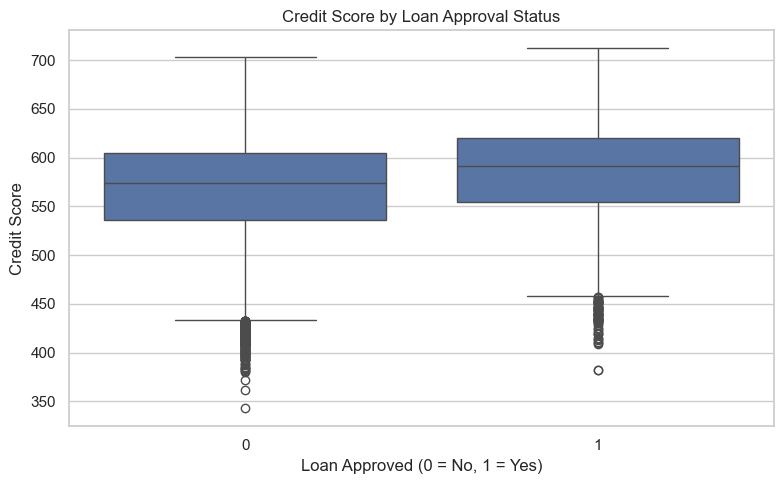

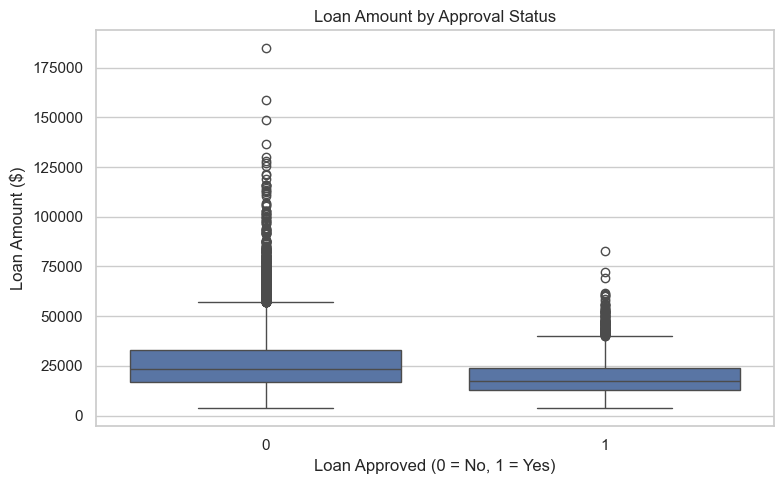

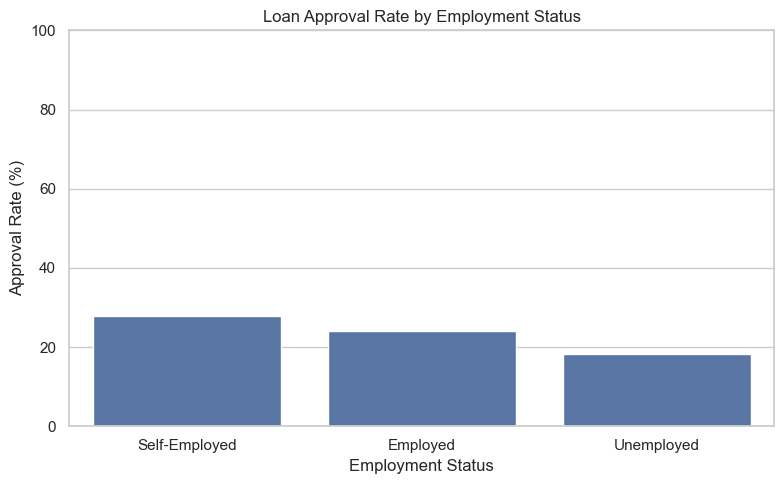

In [6]:

# Visualisation 4: Credit Score by Loan Approval
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="LoanApproved", y="CreditScore")
plt.title("Credit Score by Loan Approval Status")
plt.xlabel("Loan Approved (0 = No, 1 = Yes)")
plt.ylabel("Credit Score")
plt.tight_layout()
plt.show()

# Visualisation 5: Loan Amount by Loan Approval
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="LoanApproved", y="LoanAmount")
plt.title("Loan Amount by Approval Status")
plt.xlabel("Loan Approved (0 = No, 1 = Yes)")
plt.ylabel("Loan Amount ($)")
plt.tight_layout()
plt.show()

# Visualisation 6: Approval Rate by Employment Status
approval_rates = (
    df.groupby("EmploymentStatus")["LoanApproved"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
sns.barplot(x=approval_rates.index, y=approval_rates.values)
plt.title("Loan Approval Rate by Employment Status")
plt.xlabel("Employment Status")
plt.ylabel("Approval Rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


### Interpretation of Loan Approval Relationships

**4. Credit Score by Loan Approval Status**

- Approved applicants generally have higher credit scores than rejected applicants.
- The median credit score for approved applicants is approximately 590, compared to 575 for rejected applicants.
- Both groups contain applicants with relatively low credit scores, indicating that credit score alone does not determine approval.
- The findings suggest a positive association between credit score and loan approval.

**5. Loan Amount by Approval Status**

- Approved applicants generally request smaller loans than rejected applicants.
- The median loan amount for approved applicants is approximately $17,000, compared to $23,000 for rejected applicants.
- Rejected applications show greater variation in loan amounts, including several extreme values exceeding $100,000.
- This suggests that larger loan requests may be associated with a lower likelihood of approval, potentially reflecting greater lending exposure.

**6. Loan Approval Rate by Employment Status**

- Self-employed applicants have the highest approval rate at approximately 27%.
- Employed applicants have an approval rate of approximately 24%.
- Unemployed applicants have the lowest approval rate at approximately 18%.
- Employment status appears to be associated with loan approval outcomes, although further analysis is needed to determine whether these differences remain after accounting for other financial characteristics.

**Overall Interpretation**

The results suggest that credit scores, loan amounts and employment status are associated with historical loan approval decisions.

These relationships support including the variables in further predictive analysis, subject to data quality checks and consideration of potential bias. The observed associations do not establish causation or demonstrate that historical approval decisions accurately reflect applicants' ability to repay loans.

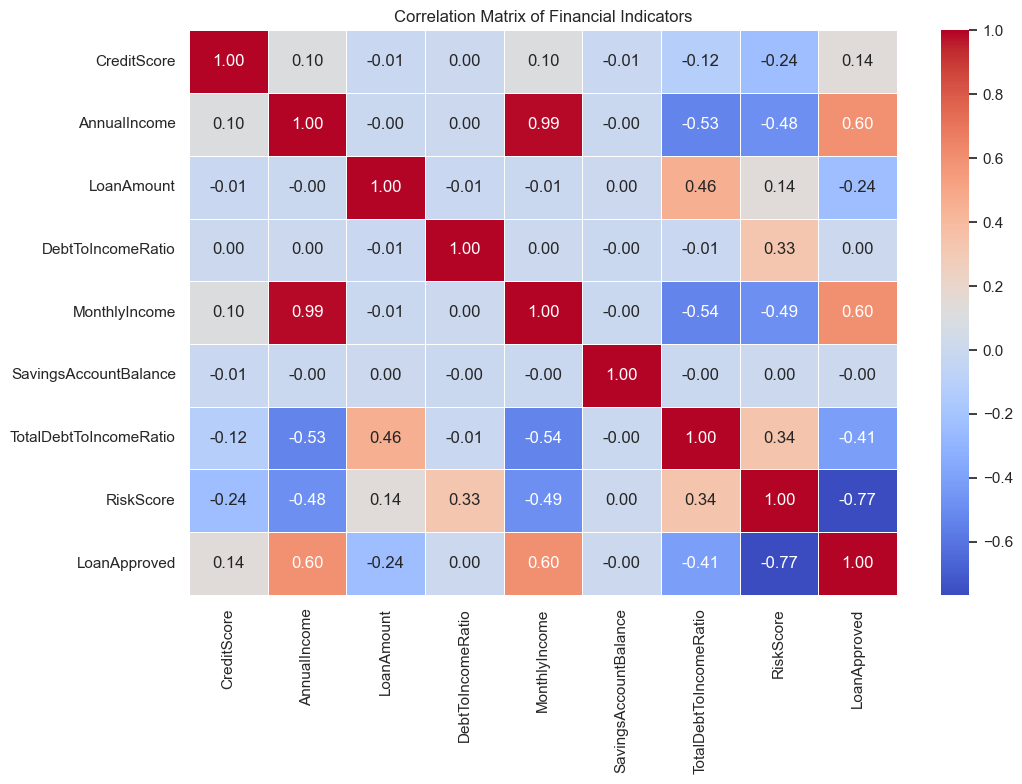

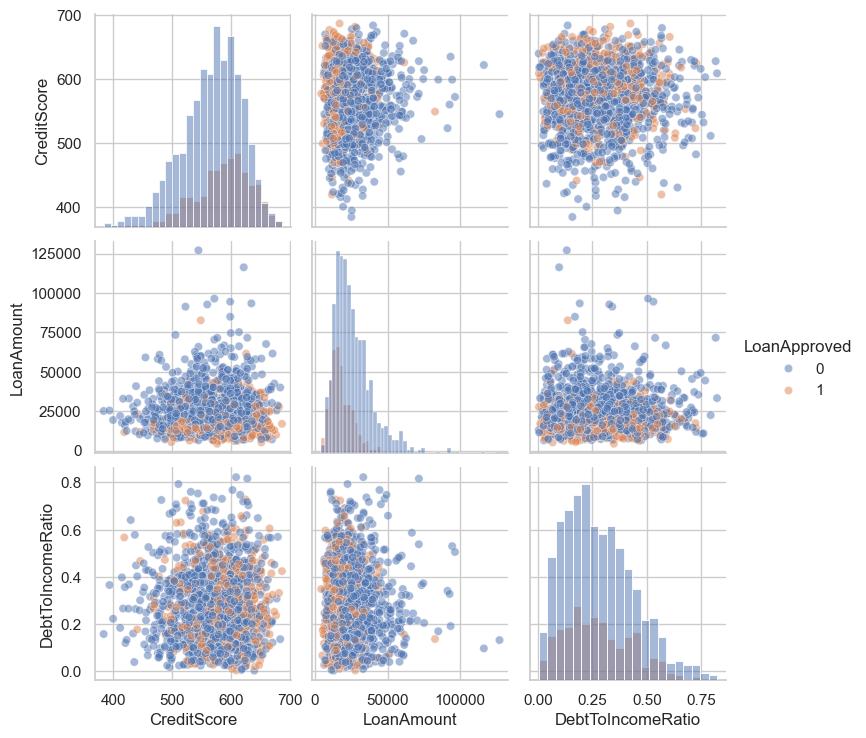

In [7]:

# Visualisation 7: Correlation Matrix
selected_features = [
    "CreditScore",
    "AnnualIncome",
    "LoanAmount",
    "DebtToIncomeRatio",
    "MonthlyIncome",
    "SavingsAccountBalance",
    "TotalDebtToIncomeRatio",
    "RiskScore",
    "LoanApproved"
]

# Convert AnnualIncome to numeric for analysis
df["AnnualIncome"] = pd.to_numeric(
    df["AnnualIncome"].astype(str)
      .str.replace(r"[$,]", "", regex=True),
    errors="coerce"
)

plt.figure(figsize=(11, 8))

correlation_matrix = df[selected_features].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Financial Indicators")
plt.tight_layout()
plt.show()


# Visualisation 8: Pair Plot
pair_features = [
    "CreditScore",
    "LoanAmount",
    "DebtToIncomeRatio",
    "LoanApproved"
]

# Sample data to improve plotting speed
pair_sample = df[pair_features].sample(
    n=1500,
    random_state=42
)

sns.pairplot(
    pair_sample,
    vars=["CreditScore", "LoanAmount", "DebtToIncomeRatio"],
    hue="LoanApproved",
    diag_kind="hist",
    plot_kws={"alpha": 0.5}
)

plt.show()


### 7. Correlation Matrix Analysis

The correlation matrix identifies relationships between financial indicators and loan approval outcomes.

**Key Findings**

- **Risk Score and Loan Approval (-0.77):** A strong negative correlation indicates that applicants with higher risk scores are less likely to receive loan approval.
- **Annual Income and Loan Approval (0.60):** A moderately strong positive relationship suggests that applicants with higher incomes are more likely to receive approval.
- **Monthly Income and Loan Approval (0.60):** Monthly income shows a similar positive relationship with approval.
- **Total Debt-to-Income Ratio and Loan Approval (-0.41):** Applicants with higher total debt burdens are less likely to receive approval.
- **Loan Amount and Loan Approval (-0.24):** Larger loan requests show a weak negative relationship with approval.
- **Credit Score and Loan Approval (0.14):** Credit score has a weak positive relationship with approval.

**Multicollinearity**

Annual Income and Monthly Income have a correlation of 0.99, indicating that they contain nearly identical information. Including both variables in a linear model could introduce multicollinearity.

During preprocessing, one of these variables may be removed to reduce redundancy.

**Potential Data Leakage**

Risk Score has a strong relationship with Loan Approval (-0.77). Before including it as a predictor, we must establish whether it was calculated before the original loan approval decision. If it incorporates approval outcomes or information unavailable at application time, including it could cause data leakage and produce misleading model performance.

### 8. Pair Plot Analysis

The pair plot examines relationships between Credit Score, Loan Amount and Debt-to-Income Ratio, grouped by loan approval status.

**Key Findings**

- **Credit Score:** Approved and rejected applicants have overlapping credit score distributions. This suggests that credit score alone cannot reliably distinguish between the two groups.
- **Loan Amount:** Approved applicants are more concentrated among smaller loan amounts, while rejected applicants show a wider distribution, including several large loan requests.
- **Debt-to-Income Ratio:** Both approval groups have overlapping distributions. The ratio alone does not provide a clear separation between approved and rejected applicants.
- **Feature Relationships:** The scatterplots do not show strong linear relationships among the three selected financial indicators.

**Business Implications**

The findings suggest that loan approval decisions depend on a combination of financial characteristics rather than a single variable.

Income, debt burden, loan amount and credit score should be considered together when developing the predictive model.

The analysis also highlights the need to investigate possible data leakage and correlated predictors before model training.

### Overall EDA Findings

The exploratory analysis indicates that:

1. Loan approval outcomes are imbalanced, with 76.1% rejected and 23.9% approved applications.
2. Income and debt-related indicators show meaningful relationships with approval outcomes.
3. Some financial variables are highly correlated and may require feature selection.
4. Outliers exist in loan amounts and other financial variables.
5. Missing values and inconsistent data types require appropriate preprocessing.
6. Risk Score requires further investigation before it can be used as a predictor.

These findings will guide the data preparation and model

In [8]:

# Step 12: Data Quality Assessment

# 1. Missing values
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

print("Missing Values:")
display(missing_summary[missing_summary["Missing Count"] > 0])

# 2. Check categorical values
categorical_columns = df.select_dtypes(include="object").columns

print("\nCategorical Variable Values:")
for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))

# 3. Detect outliers using the IQR method
numeric_columns = [
    "Age", "AnnualIncome", "CreditScore",
    "LoanAmount", "MonthlyIncome",
    "SavingsAccountBalance", "TotalDebtToIncomeRatio"
]

outlier_results = []

for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = ((df[col] < lower_bound) |
                (df[col] > upper_bound)).sum()

    outlier_results.append({
        "Feature": col,
        "Outlier Count": outliers,
        "Outlier Percentage": round(outliers / len(df) * 100, 2)
    })

print("\nPotential Outliers (IQR Method):")
display(pd.DataFrame(outlier_results))


Missing Values:


,Missing Count,Missing Percentage
EducationLevel,901,4.50
MaritalStatus,1331,6.65
SavingsAccountBalance,572,2.86



Categorical Variable Values:

EmploymentStatus:
EmploymentStatus
Employed         17036
Self-Employed     1573
Unemployed        1391
Name: count, dtype: int64

EducationLevel:
EducationLevel
Bachelor       5804
High School    5592
Associate      3850
Master         2933
Doctorate       920
NaN             901
Name: count, dtype: int64

MaritalStatus:
MaritalStatus
Married     9370
Single      5665
Divorced    2704
NaN         1331
Widowed      930
Name: count, dtype: int64

HomeOwnershipStatus:
HomeOwnershipStatus
Mortgage    7939
Rent        6087
Own         3938
Other       2036
Name: count, dtype: int64

BankruptcyHistory:
BankruptcyHistory
No     18952
Yes     1048
Name: count, dtype: int64

LoanPurpose:
LoanPurpose
Home                  5925
Debt Consolidation    5027
Auto                  4034
Education             3008
Other                 2006
Name: count, dtype: int64

Potential Outliers (IQR Method):


,Feature,Outlier Count,Outlier Percentage
0,Age,64,0.32
1,AnnualIncome,947,4.74
2,CreditScore,242,1.21
3,LoanAmount,746,3.73
4,MonthlyIncome,925,4.62
5,SavingsAccountBalance,1547,7.74
6,TotalDebtToIncomeRatio,1152,5.76


### 9. Data Quality Assessment

**9.1 Missing Values**

The dataset contains missing values in three variables:

| Variable | Missing Values | Percentage |
|---|---:|---:|
| EducationLevel | 901 | 4.50% |
| MaritalStatus | 1,331 | 6.65% |
| SavingsAccountBalance | 572 | 2.86% |

The missing values affect both categorical and numerical variables.

**Proposed Treatment:**

- **EducationLevel:** Use the most frequent category (mode) for missing values.
- **MaritalStatus:** Introduce an "Unknown" category to preserve information about missing responses.
- **SavingsAccountBalance:** Use median imputation because the variable has a right-skewed distribution and several extreme values.

Missing values will be handled within the preprocessing pipeline to prevent information from the test dataset influencing model training.

**9.2 Categorical Variables**

The categorical variables contain clearly defined categories, with no obvious inconsistencies in the displayed values.

- EmploymentStatus contains three categories.
- EducationLevel contains five observed categories.
- MaritalStatus contains four observed categories.
- HomeOwnershipStatus contains four categories.
- BankruptcyHistory contains two categories.
- LoanPurpose contains five categories.

EducationLevel has a natural order, ranging from High School to Doctorate. Ordinal encoding may be appropriate if the ordering is relevant to the model.

The remaining categorical variables will generally be handled using one-hot encoding.

**9.3 Outlier Detection**

The Interquartile Range (IQR) method identified potential outliers in several numerical variables.

| Variable | Outliers | Percentage |
|---|---:|---:|
| Age | 64 | 0.32% |
| AnnualIncome | 947 | 4.74% |
| CreditScore | 242 | 1.21% |
| LoanAmount | 746 | 3.73% |
| MonthlyIncome | 925 | 4.62% |
| SavingsAccountBalance | 1,547 | 7.74% |
| TotalDebtToIncomeRatio | 1,152 | 5.76% |

SavingsAccountBalance has the highest proportion of potential outliers at 7.74%, followed by TotalDebtToIncomeRatio at 5.76%.

These observations may represent genuine differences in applicants' financial circumstances rather than data entry errors.

**Proposed Treatment:**

- Retain plausible financial outliers rather than automatically deleting observations.
- Use median imputation for skewed numerical variables.
- Consider robust scaling or transformations for highly skewed features where appropriate.
- Assess the effect of extreme values during model development.

**9.4 Feature Engineering Opportunities**

The exploratory analysis identified several opportunities for feature selection and engineering:

- **Income:** AnnualIncome and MonthlyIncome are highly correlated (0.99). One may be excluded to reduce redundancy.
- **Debt Burden:** TotalDebtToIncomeRatio may provide useful information about an applicant's overall repayment obligations.
- **Financial Position:** NetWorth, TotalAssets and TotalLiabilities may provide overlapping information that requires further examination.
- **Risk Indicators:** RiskScore requires investigation to establish whether it was available before the loan approval decision.

Feature selection and engineering will be performed within the training process where appropriate to avoid data leakage.

### 10. Data Understanding Conclusion

The dataset contains 20,000 loan applications and 35 variables, including the target variable LoanApproved.

The analysis identified class imbalance, missing values, skewed financial variables, potential outliers and highly correlated predictors.

These findings support the development of a preprocessing pipeline that handles numerical and categorical features separately.

The next phase will focus on preparing the data for model training while preserving information and preventing data leakage.

## Data Preparation
### Question 5: Preprocessing Strategy

The dataset contains numerical, categorical and ordinal features that require different preprocessing methods.

The preprocessing strategy aims to address missing values, convert categorical variables into numerical representations, scale numerical features and reduce the risk of data leakage.

**1. Target Variable and Feature Selection**

LoanApproved is selected as the target variable for the classification model.

RiskScore will be excluded because its availability at the time of the original loan decision has not been established. InterestRate, BaseInterestRate and MonthlyLoanPayment will also be excluded as a precaution against using information that may have been generated during or after the approval process.

MonthlyIncome will be excluded because it is highly correlated with AnnualIncome (0.99).

**2. Numerical Features**

- Missing numerical values will be replaced using median imputation.
- StandardScaler will standardise numerical features for models sensitive to feature magnitude.
- Potential outliers will initially be retained because they may represent genuine financial circumstances.

**3. Categorical Features**

- Missing EducationLevel values will be replaced using the most frequent category.
- Missing MaritalStatus values will be assigned an "Unknown" category.
- Nominal categorical variables will be converted using OneHotEncoder.

**4. Ordinal Features**

EducationLevel will be treated as an ordinal variable, with categories ordered from High School to Doctorate.

**5. Data Splitting**

The dataset will be divided into 80% training data and 20% testing data.

Stratified sampling will preserve the original proportions of approved and rejected applications.

**6. Pipeline Design**

ColumnTransformer will apply separate preprocessing steps to numerical, nominal and ordinal variables.

The preprocessing transformer will be combined with machine learning algorithms using scikit-learn Pipeline.

Imputation, scaling and encoding will be fitted only on training data within the model pipeline to prevent data leakage.


In [9]:
# Data Prep Code Here - Create New Cells As Needed

# Question 5: Data Preparation and Preprocessing Pipeline

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    OrdinalEncoder
)

# Create a copy of the dataset
data = df.copy()

# Ensure AnnualIncome is numeric
data["AnnualIncome"] = pd.to_numeric(
    data["AnnualIncome"].astype(str)
    .str.replace(r"[$,]", "", regex=True),
    errors="coerce"
)

# Define target variable
y = data["LoanApproved"]

# Exclude target and potentially problematic predictors
excluded_columns = [
    "LoanApproved",
    "RiskScore",
    "InterestRate",
    "BaseInterestRate",
    "MonthlyLoanPayment",
    "MonthlyIncome"
]

X = data.drop(columns=excluded_columns)

# Split the data before fitting preprocessing steps
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Identify feature types
ordinal_features = ["EducationLevel"]
unknown_features = ["MaritalStatus"]

nominal_features = [
    "EmploymentStatus",
    "MaritalStatus",
    "HomeOwnershipStatus",
    "BankruptcyHistory",
    "LoanPurpose"
]

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Numerical preprocessing
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Nominal categorical preprocessing
# Missing values become an explicit category
nominal_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# Ordinal preprocessing
education_order = [
    "High School",
    "Associate",
    "Bachelor",
    "Master",
    "Doctorate"
]

ordinal_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        categories=[education_order],
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("nominal", nominal_pipeline, nominal_features),
        ("ordinal", ordinal_pipeline, ordinal_features)
    ]
)

# Display preparation summary
print("Training Set Shape:", X_train.shape)
print("Testing Set Shape:", X_test.shape)

print("\nNumerical Features:", len(numeric_features))
print("Nominal Features:", len(nominal_features))
print("Ordinal Features:", len(ordinal_features))

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True).round(3))

print("\nPreprocessing pipeline created successfully.")


Training Set Shape: (16000, 29)
Testing Set Shape: (4000, 29)

Numerical Features: 23
Nominal Features: 5
Ordinal Features: 1

Training Target Distribution:
LoanApproved
0    0.761
1    0.239
Name: proportion, dtype: float64

Testing Target Distribution:
LoanApproved
0    0.761
1    0.239
Name: proportion, dtype: float64

Preprocessing pipeline created successfully.


### Question 5: Data Preparation Results and Interpretation

The dataset was successfully divided into training and testing sets using an 80:20 stratified split.

The training set contains 16,000 observations, while the testing set contains 4,000 observations. Both datasets contain 29 predictor variables.

The preprocessing strategy identified:

- 23 numerical features requiring median imputation and standardisation.
- 5 nominal categorical features requiring missing-value treatment and one-hot encoding.
- 1 ordinal feature (EducationLevel) requiring ordered encoding.

**Class Distribution**

Both datasets maintain the original loan approval distribution:

- Rejected applications: 76.1%
- Approved applications: 23.9%

Preserving these proportions ensures that both datasets reflect the original class imbalance.

**Preprocessing Pipeline**

A ColumnTransformer was successfully defined to apply different preprocessing methods based on feature type.

The preprocessing steps will be fitted using training data within the machine learning pipelines. This approach reduces the risk of data leakage and ensures consistent processing during model training and evaluation.

**Conclusion**

The data preparation stage has established the feature selection, training/testing split and preprocessing structure required for model development.

The next phase will compare classification algorithms to identify a model that balances predictive performance, interpretability and the financial consequences of incorrect loan approval decisions.

## Modeling
### Question 6: Modeling Approach

**1. Model Selection**

This project uses supervised machine learning classification to predict whether a loan application will be approved (1) or rejected (0).

Five classification algorithms will be compared:

- **Logistic Regression:** Provides an interpretable baseline for understanding how applicant characteristics relate to loan approval.
- **Decision Tree:** Captures non-linear relationships and produces decision rules that are relatively easy to interpret.
- **Random Forest:** Combines multiple decision trees to improve predictive performance and reduce overfitting.
- **Gradient Boosting:** Builds sequential models to correct prediction errors and capture complex relationships.
- **Extra Trees:** Uses randomised decision trees to provide an alternative ensemble approach.

**2. Validation Strategy**

The dataset has already been divided into 80% training data and 20% testing data using stratified sampling.

Five-fold Stratified Cross-Validation will be applied to the training dataset to compare model performance while preserving the class distribution.

The testing dataset will remain separate for final evaluation.

**3. Evaluation Metrics**

Model performance will be assessed using:

- **Precision:** Measures the proportion of predicted approvals that were actually approved.
- **Recall:** Measures the proportion of actual approvals correctly identified.
- **F1-score:** Balances precision and recall.
- **ROC-AUC:** Measures how well a model distinguishes approved from rejected applications.
- **Accuracy:** Measures overall correct predictions but will not be the primary metric because the dataset is imbalanced.

F1-score will serve as the initial model selection metric, supported by ROC-AUC, precision and recall.

**4. Model Pipelines**

Each classifier will be combined with the preprocessing steps developed in Question 5 using scikit-learn Pipeline.

This ensures that missing-value treatment, categorical encoding and numerical scaling are performed consistently within each cross-validation fold, reducing data leakage.

**5. Business Considerations**

The model predicts historical loan approval decisions rather than actual loan defaults. Therefore, its performance measures agreement with historical decisions, not the financial risk of future defaults.

False approvals and false rejections will be examined separately, recognising that they may have different business consequences.




In [10]:
#  Modeling Code Here - Create New Cells as Needed

from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier
)
import pandas as pd

# Define classification models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced",
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, class_weight="balanced",
        random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=100, class_weight="balanced",
        random_state=42, n_jobs=-1
    )
}

# Five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

# Evaluation metrics
scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC_AUC": "roc_auc"
}

# Compare models
results = []

for name, model in models.items():
    print(f"Evaluating {name}...")

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1
    )

    results.append({
        "Model": name,
        "Accuracy": scores["test_Accuracy"].mean(),
        "Precision": scores["test_Precision"].mean(),
        "Recall": scores["test_Recall"].mean(),
        "F1": scores["test_F1"].mean(),
        "ROC-AUC": scores["test_ROC_AUC"].mean()
    })

# Display comparison
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="F1", ascending=False
)

display(results_df.round(4))


Evaluating Logistic Regression...
Evaluating Decision Tree...
Evaluating Random Forest...
Evaluating Gradient Boosting...
Evaluating Extra Trees...


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.9159,0.7667,0.9317,0.8412,0.9789
3,Gradient Boosting,0.9251,0.8659,0.8128,0.8384,0.9738
2,Random Forest,0.9072,0.8619,0.7283,0.7895,0.9648
4,Extra Trees,0.8966,0.9267,0.6161,0.7399,0.9682
1,Decision Tree,0.8676,0.7279,0.7126,0.7201,0.8145


### Question 6: Model Evaluation Results and Interpretation

Five classification algorithms were evaluated using five-fold stratified cross-validation on the training dataset.

**Key Findings**

1. **Logistic Regression** achieved the highest F1-score (84.12%), recall (93.17%) and ROC-AUC (97.89%). This indicates strong performance in identifying historically approved loan applications.

2. **Gradient Boosting** achieved the highest accuracy (92.51%), with an F1-score of 83.84% and precision of 86.59%. Its performance suggests a good balance between identifying approvals and limiting incorrect approval predictions.

3. **Random Forest** achieved an F1-score of 78.95%, performing below Logistic Regression and Gradient Boosting.

4. **Extra Trees** recorded the highest precision (92.67%) but relatively low recall (61.61%), indicating that it identifies fewer actual approvals.

5. **Decision Tree** had the lowest F1-score (72.01%) and ROC-AUC (81.45%), suggesting weaker classification performance.

**Model Selection**

Logistic Regression and Gradient Boosting were selected for further tuning because they achieved the strongest F1-scores and ROC-AUC values.

Logistic Regression provides a relatively interpretable model, while Gradient Boosting offers an alternative capable of capturing more complex relationships.

**Business Implications**

The results indicate that machine learning models can reproduce historical loan approval decisions with relatively high accuracy.

Since only 23.9% of applications were approved, F1-score, precision, recall and ROC-AUC provide more meaningful performance measures than accuracy alone.

The models should not yet be interpreted as predicting actual loan defaults, since the target variable represents historical approval decisions rather than repayment outcomes.

Final model selection will consider predictive performance, interpretability and the consequences of incorrect approval predictions.

In [11]:

# Check potential data leakage

# 1. Correlation with loan approval
features_to_check = [
    "RiskScore",
    "InterestRate",
    "BaseInterestRate",
    "MonthlyLoanPayment",
    "TotalDebtToIncomeRatio",
    "CreditScore"
]

print("Correlation with Loan Approval:")
print(
    df[features_to_check + ["LoanApproved"]]
    .corr()["LoanApproved"]
    .sort_values()
)

# 2. Compare RiskScore across approval outcomes
print("\nRiskScore by Loan Approval Status:")
display(
    df.groupby("LoanApproved")["RiskScore"].describe().round(2)
)

# 3. Check approval rates across RiskScore ranges
print("\nApproval Rates by RiskScore Range:")

risk_groups = pd.cut(
    df["RiskScore"],
    bins=[0, 30, 40, 50, 60, 70, 100],
    include_lowest=True
)

approval_rates = (
    df.groupby(risk_groups, observed=True)["LoanApproved"]
    .agg(["count", "mean"])
)

approval_rates["mean"] = approval_rates["mean"] * 100
approval_rates.columns = ["Applicants", "Approval Rate (%)"]

display(approval_rates.round(2))


Correlation with Loan Approval:
RiskScore                -0.766137
TotalDebtToIncomeRatio   -0.410399
InterestRate             -0.301646
BaseInterestRate         -0.247263
MonthlyLoanPayment       -0.184272
CreditScore               0.142000
LoanApproved              1.000000
Name: LoanApproved, dtype: float64

RiskScore by Loan Approval Status:


,count,mean,std,min,25%,50%,75%,max
LoanApproved,,,,,,,,
0,15220.0,54.11,5.30,38.0,50.0,54.0,57.0,84.0
1,4780.0,40.13,3.88,28.8,37.6,40.0,42.4,56.0



Approval Rates by RiskScore Range:


,Applicants,Approval Rate (%)
RiskScore,,
"(-0.001, 30.0]",11,100.00
"(30.0, 40.0]",2623,99.58
"(40.0, 50.0]",5913,35.45
"(50.0, 60.0]",9753,0.63
"(60.0, 70.0]",1597,0.00
"(70.0, 100.0]",103,0.00


### Data Leakage Investigation and Findings

A review of the supplied dataset generation script confirmed that `RiskScore` is calculated after the `LoanApproved` variable has been generated.

The calculation explicitly reduces RiskScore by 20% for approved applications. This creates target leakage because RiskScore contains information derived from the outcome being predicted.

RiskScore was therefore excluded from the modeling features during data preparation.

The script also shows that interest rates and monthly loan payments are calculated before the approval outcome. These variables are not confirmed sources of target leakage, although they were excluded from the primary model to focus on applicant and loan characteristics.

The dataset is synthetically generated using predefined approval rules. Therefore, model performance measures the ability to reproduce these simulated decisions rather than predict actual loan repayment or default.

**Conclusion:** The existing preprocessing and model comparison remain valid for the selected feature set. No changes to Question 6 are required before hyperparameter tuning.

### Question 7: Hyperparameter Tuning

**Objective**

The objective of hyperparameter tuning is to improve model performance by identifying suitable parameter combinations.

Based on the five-fold cross-validation results from Question 6, Logistic Regression and Gradient Boosting were selected for tuning because they achieved the highest F1-scores.

**Tuning Approach**

RandomizedSearchCV will be applied to both models using five-fold stratified cross-validation.

The tuning process will examine:

- **Logistic Regression:** Regularization strength (C) and class weighting.
- **Gradient Boosting:** Number of trees, learning rate, maximum tree depth, minimum samples per leaf and subsampling ratio.
- **Preprocessing:** Alternative numerical imputation strategies.

F1-score will be used as the primary scoring metric to balance precision and recall.

Each model will be evaluated through a complete pipeline containing preprocessing and classification. This ensures that preprocessing is fitted only on the training portion of each cross-validation fold.

The test dataset will remain untouched until the final model evaluation.

**Model Selection**

The tuned models will be compared against their baseline performance using F1-score and ROC-AUC. Model complexity, interpretability and computational requirements will also be considered.

In [12]:

from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from scipy.stats import loguniform
import pandas as pd

# Create Logistic Regression pipeline
lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Define hyperparameter search space
lr_param_distributions = {
    "classifier__C": loguniform(0.001, 100),
    "classifier__class_weight": [None, "balanced"],
    "preprocessor__numeric__imputer__strategy": [
        "mean", "median"
    ]
}

# Configure randomized search
lr_search = RandomizedSearchCV(
    estimator=lr_pipeline,
    param_distributions=lr_param_distributions,
    n_iter=20,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    return_train_score=True
)

# Run hyperparameter tuning
lr_search.fit(X_train, y_train)

# Display best results
print("Best Logistic Regression Parameters:")
print(lr_search.best_params_)

print("\nBest Cross-Validation F1-score:")
print(round(lr_search.best_score_, 4))

# Compare baseline and tuned performance
lr_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression - Baseline",
        "Logistic Regression - Tuned"
    ],
    "CV F1-score": [
        0.8412,
        lr_search.best_score_
    ]
})

display(lr_comparison.round(4))


Best Logistic Regression Parameters:
{'classifier__C': np.float64(2.6373339933815254), 'classifier__class_weight': None, 'preprocessor__numeric__imputer__strategy': 'median'}

Best Cross-Validation F1-score:
0.8506


,Model,CV F1-score
0,Logistic Regression - Baseline,0.8412
1,Logistic Regression - Tuned,0.8506


### Logistic Regression Tuning Results

RandomizedSearchCV was applied to Logistic Regression using 20 parameter combinations and five-fold stratified cross-validation.

The best parameter combination was:

- Regularization strength (C): 2.6373
- Class weight: None
- Numerical imputation: Median

The baseline F1-score was 0.8412, while the tuned model achieved an F1-score of 0.8506.

This represents an improvement of 0.0094 (0.94 percentage points).

The results suggest that adjusting regularization strength and removing automatic class weighting improved the model's balance between precision and recall.

The improvement is relatively small. The tuned model will therefore be compared with Gradient Boosting before selecting the final model.

In [13]:

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
import pandas as pd

# Create Gradient Boosting pipeline
gb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(
        random_state=42
    ))
])

# Define hyperparameter search space
gb_param_distributions = {
    "classifier__n_estimators": [50, 100, 150, 200],
    "classifier__learning_rate": [0.01, 0.05, 0.1, 0.2],
    "classifier__max_depth": [2, 3, 4],
    "classifier__min_samples_leaf": [1, 5, 10],
    "classifier__subsample": [0.8, 1.0],
    "preprocessor__numeric__imputer__strategy": [
        "mean", "median"
    ]
}

# Configure randomized search
gb_search = RandomizedSearchCV(
    estimator=gb_pipeline,
    param_distributions=gb_param_distributions,
    n_iter=12,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    return_train_score=True
)

# Run hyperparameter tuning
gb_search.fit(X_train, y_train)

# Display best parameters
print("Best Gradient Boosting Parameters:")
print(gb_search.best_params_)

print("\nBest Cross-Validation F1-score:")
print(round(gb_search.best_score_, 4))

# Compare baseline and tuned performance
gb_comparison = pd.DataFrame({
    "Model": [
        "Gradient Boosting - Baseline",
        "Gradient Boosting - Tuned"
    ],
    "CV F1-score": [
        0.8384,
        gb_search.best_score_
    ]
})

display(gb_comparison.round(4))


Best Gradient Boosting Parameters:
{'preprocessor__numeric__imputer__strategy': 'mean', 'classifier__subsample': 0.8, 'classifier__n_estimators': 200, 'classifier__min_samples_leaf': 10, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.1}

Best Cross-Validation F1-score:
0.8474


,Model,CV F1-score
0,Gradient Boosting - Baseline,0.8384
1,Gradient Boosting - Tuned,0.8474


### Gradient Boosting Tuning Results

Gradient Boosting was tuned using RandomizedSearchCV with 12 parameter combinations and five-fold stratified cross-validation.

The best parameter combination was:

- Learning rate: 0.1
- Number of estimators: 200
- Maximum tree depth: 3
- Minimum samples per leaf: 10
- Subsample ratio: 0.8
- Numerical imputation: Mean

The baseline F1-score was 0.8384, while the tuned model achieved 0.8474, representing an improvement of 0.0090 (0.90 percentage points).

### Comparison and Model Selection

Both selected models improved following hyperparameter tuning.

Tuned Logistic Regression achieved the highest cross-validation F1-score of 0.8506, compared with 0.8474 for tuned Gradient Boosting.

Logistic Regression was selected as the preferred model because of its slightly higher F1-score and greater interpretability.

Gradient Boosting will be retained as a comparison model during final evaluation.

The final test dataset has not been used during model selection or hyperparameter tuning, preserving it for an independent assessment of model performance.

## Evaluation and Conclusion
### Question 8: Final Model Evaluation

This section evaluates the tuned classification models
using the previously unseen test dataset.

The evaluation includes classification metrics,
confusion matrices, ROC curves, performance across
applicant segments, and potential model limitations.

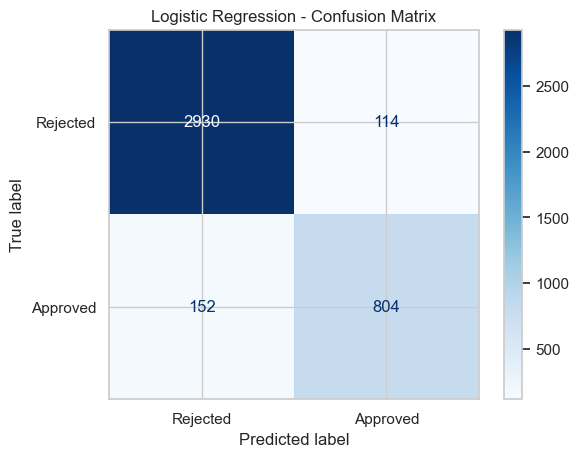

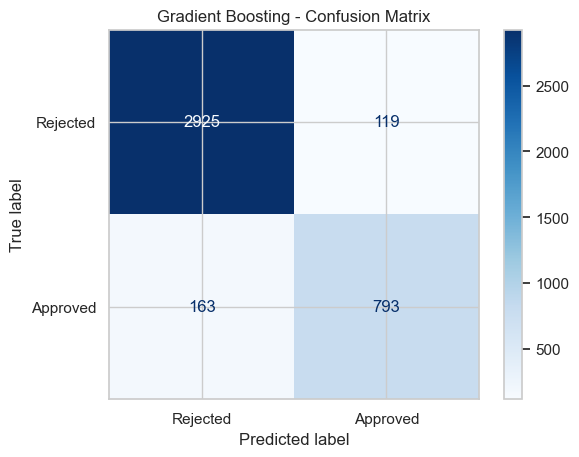

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.9335,0.8758,0.8410,0.8581,0.9784
1,Gradient Boosting,0.9295,0.8695,0.8295,0.8490,0.9774


In [14]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import pandas as pd

# Retrieve tuned models
final_models = {
    "Logistic Regression": lr_search.best_estimator_,
    "Gradient Boosting": gb_search.best_estimator_
}

evaluation_results = []

for name, model in final_models.items():

    # Predictions on the untouched test dataset
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    # Display confusion matrix
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["Rejected", "Approved"],
        cmap="Blues"
    )

    plt.title(f"{name} - Confusion Matrix")
    plt.show()

# Display final comparison
evaluation_df = pd.DataFrame(evaluation_results)

display(
    evaluation_df.sort_values(
        by="F1", ascending=False
    ).round(4)
)


### Question 8: Test Dataset Performance and Interpretation

Both tuned models were evaluated using the previously unseen test dataset containing 4,000 loan applications.

**Model Performance**

Logistic Regression achieved an accuracy of 93.35%, precision of 87.58%, recall of 84.10%, F1-score of 85.81% and ROC-AUC of 97.84%.

Gradient Boosting achieved an accuracy of 92.95%, precision of 86.95%, recall of 82.95%, F1-score of 84.90% and ROC-AUC of 97.74%.

Logistic Regression performed slightly better across all five evaluation metrics.

**Confusion Matrix Analysis**

Logistic Regression correctly classified 2,930 rejected applications and 804 approved applications. It incorrectly classified 114 rejected applications as approved and 152 approved applications as rejected.

Gradient Boosting correctly classified 2,925 rejected applications and 793 approved applications. It incorrectly classified 119 rejected applications as approved and 163 approved applications as rejected.

Logistic Regression produced 266 incorrect predictions, compared with 282 for Gradient Boosting.

**Model Selection**

Logistic Regression was selected as the preferred model because it achieved the highest F1-score, ROC-AUC and accuracy on the test dataset.

Its test F1-score of 0.8581 was also reasonably close to its tuned cross-validation score of 0.8506, suggesting consistent performance on unseen data.

The results demonstrate that the model can predict historical simulated loan approval decisions with relatively high accuracy. They do not establish its ability to predict actual loan defaults.

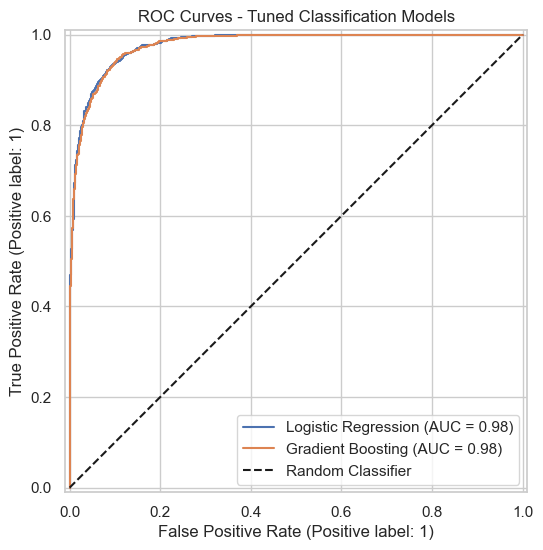

In [15]:

from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6))

for name, model in final_models.items():
    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=name,
        ax=ax
    )

ax.plot([0, 1], [0, 1], "k--", label="Random Classifier")
ax.set_title("ROC Curves - Tuned Classification Models")
ax.legend(loc="lower right")

plt.show()


### ROC Curve Analysis

The ROC curves were used to assess the ability of the tuned models to distinguish between historically approved and rejected loan applications across different classification thresholds.

Logistic Regression achieved a ROC-AUC of 0.9784, while Gradient Boosting achieved 0.9774.

Both curves are positioned close to the upper-left corner, indicating strong discrimination between the two classes.

Logistic Regression achieved a slightly higher ROC-AUC, although the difference of 0.0010 indicates that both models have comparable discrimination performance.

These results support the selection of Logistic Regression as the preferred model based on its combined F1-score, ROC-AUC and interpretability.

The findings relate to historical simulated approval decisions rather than actual loan repayment outcomes.

In [16]:

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)
import pandas as pd
import numpy as np

# Predictions from the selected model
best_model = lr_search.best_estimator_
y_pred = best_model.predict(X_test)

# Create evaluation dataset
segment_df = X_test.copy()
segment_df["Actual"] = y_test.to_numpy()
segment_df["Predicted"] = y_pred

# Create age groups
segment_df["AgeGroup"] = pd.cut(
    segment_df["Age"],
    bins=[17, 30, 45, 60, np.inf],
    labels=["18-30", "31-45", "46-60", "61+"]
)

# Function to calculate performance by segment
def evaluate_segments(data, group_column):
    results = []

    for group, subset in data.groupby(
        group_column, observed=True, dropna=False
    ):
        actual = subset["Actual"]
        predicted = subset["Predicted"]

        results.append({
            "Segment": str(group),
            "Applicants": len(subset),
            "Accuracy": accuracy_score(actual, predicted),
            "Precision": precision_score(
                actual, predicted, zero_division=0
            ),
            "Recall": recall_score(
                actual, predicted, zero_division=0
            ),
            "F1": f1_score(
                actual, predicted, zero_division=0
            ),
            "False Approval Rate": (
                ((actual == 0) & (predicted == 1)).sum()
                / max((actual == 0).sum(), 1)
            ),
            "False Rejection Rate": (
                ((actual == 1) & (predicted == 0)).sum()
                / max((actual == 1).sum(), 1)
            )
        })

    return pd.DataFrame(results).round(4)

# Evaluate age groups
print("Performance by Age Group:")
display(evaluate_segments(segment_df, "AgeGroup"))

# Evaluate employment status
print("\nPerformance by Employment Status:")
display(evaluate_segments(segment_df, "EmploymentStatus"))

# Evaluate education level
print("\nPerformance by Education Level:")
display(evaluate_segments(segment_df, "EducationLevel"))


Performance by Age Group:


,Segment,Applicants,Accuracy,Precision,Recall,F1,False Approval Rate,False Rejection Rate
0,18-30,870,0.9483,0.8051,0.8120,0.8085,0.0305,0.1880
1,31-45,1890,0.9275,0.8842,0.8095,0.8452,0.0343,0.1905
2,46-60,1085,0.9318,0.8946,0.8723,0.8833,0.0432,0.1277
3,61+,155,0.9355,0.8594,0.9821,0.9167,0.0909,0.0179



Performance by Employment Status:


,Segment,Applicants,Accuracy,Precision,Recall,F1,False Approval Rate,False Rejection Rate
0,Employed,3402,0.9362,0.8818,0.8507,0.8660,0.0365,0.1493
1,Self-Employed,311,0.9035,0.8514,0.7683,0.8077,0.0480,0.2317
2,Unemployed,287,0.9338,0.8163,0.8000,0.8081,0.0380,0.2000



Performance by Education Level:


,Segment,Applicants,Accuracy,Precision,Recall,F1,False Approval Rate,False Rejection Rate
0,Associate,782,0.9182,0.8311,0.7593,0.7935,0.0403,0.2407
1,Bachelor,1163,0.9312,0.8840,0.8677,0.8758,0.0442,0.1323
2,Doctorate,156,0.9103,0.9104,0.8841,0.8971,0.0690,0.1159
3,High School,1086,0.9595,0.9013,0.8253,0.8616,0.0163,0.1747
4,Master,620,0.9065,0.8894,0.8590,0.8739,0.0648,0.1410
5,nan,193,0.9689,0.0000,0.0000,0.0000,0.0311,0.0000


### Segment Performance Analysis and Model Limitations

The selected Logistic Regression model was evaluated across age groups, employment status and education levels to identify differences in classification performance.

**Age Groups**

The model recorded higher false rejection rates among applicants aged 18–30 (18.80%) and 31–45 (19.05%) compared with applicants aged 46–60 (12.77%).

Applicants aged 61 and above recorded the lowest false rejection rate (1.79%) but the highest false approval rate (9.09%). This group contained only 155 applicants, making its estimates less reliable.

**Employment Status**

Self-employed applicants recorded the highest false rejection rate (23.17%), followed by unemployed applicants (20.00%) and employed applicants (14.93%).

These differences suggest that the model's ability to identify historically approved applications varies by employment category.

**Education Level**

Applicants with Associate-level education recorded the highest false rejection rate (24.07%).

Applicants with missing education information recorded an F1-score of zero despite high accuracy. This result requires further investigation to establish whether the group contains any historically approved applications.

**Potential Biases and Limitations**

The differences in error rates across applicant groups indicate potential disparities in model performance.

These differences do not independently establish unfair discrimination. They may reflect differences in the underlying synthetic approval rules, group characteristics or sample sizes.

The dataset is synthetic and the target represents simulated loan approval decisions rather than actual loan repayment outcomes.

Before any practical use, the model would require validation using real lending data, assessment of fairness across applicant groups and confirmation that the selected predictors comply with applicable lending requirements.

**Overall Assessment**

Logistic Regression achieved strong overall predictive performance, but the segment analysis shows that performance is not uniform across applicant groups.

These findings support the need for further fairness testing and ongoing monitoring before considering the model for real-world decision-making.

In [17]:

# Investigate missing EducationLevel records

missing_education = segment_df[
    segment_df["EducationLevel"].isna()
]

print("Actual Approval Distribution:")
print(missing_education["Actual"].value_counts())

print("\nPredicted Approval Distribution:")
print(missing_education["Predicted"].value_counts())

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        missing_education["Actual"],
        missing_education["Predicted"],
        labels=[0, 1]
    )
)


Actual Approval Distribution:
Actual
0    193
Name: count, dtype: int64

Predicted Approval Distribution:
Predicted
0    187
1      6
Name: count, dtype: int64

Confusion Matrix:
[[187   6]
 [  0   0]]


### Investigation of Missing Education Records

Further analysis was conducted on the 193 applicants with missing education information.

All 193 applications were historically rejected. The Logistic Regression model correctly predicted 187 rejections and incorrectly predicted six applications as approved.

This resulted in an accuracy of 96.89% and a false approval rate of 3.11%.

The F1-score of zero does not indicate poor overall classification performance in this group. It occurs because there were no actual approved applications, making positive-class recall undefined.

The absence of approved applications among respondents with missing education information may reflect characteristics of the synthetic dataset or its approval rules.

This finding highlights the importance of examining class distributions when interpreting performance metrics across applicant segments.

Further investigation would be required before drawing conclusions about fairness or discrimination based on missing education information.

### Question 9: Feature Importance and Interpretation

**Objective**

This section examines the features that have the greatest influence on the selected Logistic Regression model's predictions.

Logistic Regression coefficients will be extracted from the fitted model pipeline to assess the direction and relative strength of each feature's relationship with predicted loan approval.

- Positive coefficients indicate an increase in the predicted log-odds of loan approval.
- Negative coefficients indicate a decrease in the predicted log-odds of loan approval.
- Larger absolute coefficients indicate stronger model associations, subject to differences in feature scaling and encoding.

The analysis will identify the most influential predictors and examine their implications for loan approval decisions.

Since the dataset is synthetic, these relationships will be interpreted as characteristics of the simulated approval process rather than evidence of actual lending behaviour.

Top 15 Most Influential Features:


,Feature,Coefficient,Absolute Importance
22,numeric__TotalDebtToIncomeRatio,-6.6765,6.6765
36,nominal__BankruptcyHistory_Yes,-3.6711,3.6711
25,nominal__EmploymentStatus_Unemployed,-2.2673,2.2673
1,numeric__AnnualIncome,2.0819,2.0819
5,numeric__LoanDuration,-1.5910,1.5910
4,numeric__LoanAmount,-1.4202,1.4202
21,numeric__NetWorth,1.4095,1.4095
32,nominal__HomeOwnershipStatus_Other,-1.2728,1.2728
34,nominal__HomeOwnershipStatus_Rent,-1.2230,1.2230
30,nominal__MaritalStatus_Widowed,-1.0999,1.0999


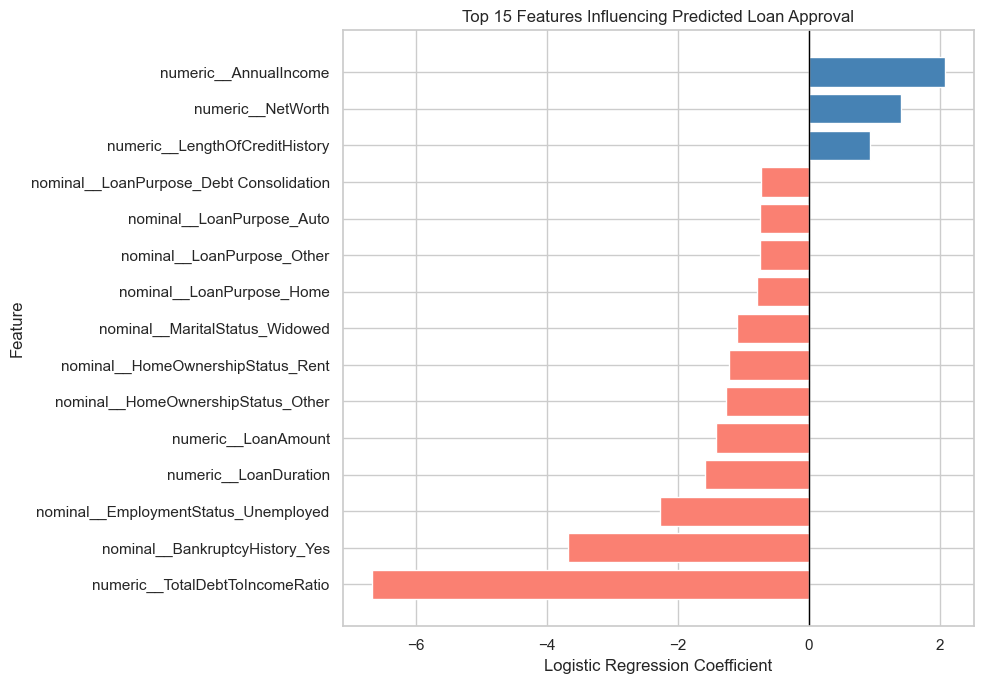

In [18]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Retrieve the tuned Logistic Regression pipeline
best_model = lr_search.best_estimator_

# Extract fitted preprocessing and classification steps
fitted_preprocessor = best_model.named_steps["preprocessor"]
logistic_model = best_model.named_steps["classifier"]

# Retrieve feature names after preprocessing
feature_names = fitted_preprocessor.get_feature_names_out()

# Extract Logistic Regression coefficients
coefficients = logistic_model.coef_[0]

# Create feature importance table
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Absolute Importance": np.abs(coefficients)
})

# Sort features by absolute coefficient value
feature_importance_df = feature_importance_df.sort_values(
    by="Absolute Importance",
    ascending=False
)

# Display the 15 most influential encoded features
print("Top 15 Most Influential Features:")
display(feature_importance_df.head(15).round(4))

# Plot the top 15 coefficients
top_features = (
    feature_importance_df.head(15)
    .sort_values("Coefficient")
)

plt.figure(figsize=(10, 7))

colors = [
    "steelblue" if coef > 0 else "salmon"
    for coef in top_features["Coefficient"]
]

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"],
    color=colors
)

plt.axvline(0, color="black", linewidth=1)

plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.title("Top 15 Features Influencing Predicted Loan Approval")

plt.tight_layout()
plt.show()


### Question 9: Feature Importance Results and Interpretation

The coefficients of the tuned Logistic Regression model were examined to identify the features most strongly associated with predicted loan approval.

**Key Findings**

1. **Total Debt-to-Income Ratio:** This recorded the largest absolute coefficient (−6.6765), indicating a strong negative association with predicted loan approval. Higher debt obligations relative to income reduce the model's predicted approval probability.

2. **Bankruptcy History:** A recorded bankruptcy had a negative coefficient of −3.6711, suggesting that applicants with a bankruptcy history are less likely to receive a positive prediction.

3. **Employment Status:** Unemployment had a negative coefficient of −2.2673, indicating a lower predicted approval probability for unemployed applicants.

4. **Annual Income:** Annual income had a positive coefficient of 2.0819, suggesting that applicants with higher incomes are more likely to receive positive predictions.

5. **Loan Characteristics:** Loan duration (−1.5910) and loan amount (−1.4202) were negatively associated with approval.

6. **Financial Position:** Net worth (1.4095) and length of credit history (0.9396) were positively associated with approval.

**Business Implications**

The findings suggest that debt affordability, financial position, credit history and loan characteristics are important factors in the simulated approval process.

For practical lending applications, financial assessments could place greater emphasis on applicants' repayment capacity, existing debt obligations and credit history.

The model could also support the identification of applications requiring further assessment rather than relying exclusively on automated decisions.

**Limitations**

The coefficients reflect relationships learned from a synthetic dataset and should not be interpreted as causal effects.

Numerical and categorical features were processed using different scaling methods, meaning coefficient magnitudes are not directly comparable across all feature types.

Some variables, including age, marital status and education, may raise fairness concerns in lending decisions. Their use would require further assessment before deployment.

The model predicts simulated historical approvals rather than actual loan defaults. Therefore, the findings cannot establish whether applicants would repay their loans.

Top 15 Features by Permutation Importance:


,Feature,Importance,Std
28,TotalDebtToIncomeRatio,0.3064,0.0067
1,AnnualIncome,0.1955,0.0031
7,LoanDuration,0.0832,0.0018
6,LoanAmount,0.0605,0.0018
27,NetWorth,0.0571,0.0026
20,LengthOfCreditHistory,0.0394,0.0017
4,EducationLevel,0.0299,0.0009
16,BankruptcyHistory,0.0210,0.0012
18,PreviousLoanDefaults,0.0180,0.0015
10,HomeOwnershipStatus,0.0082,0.0018


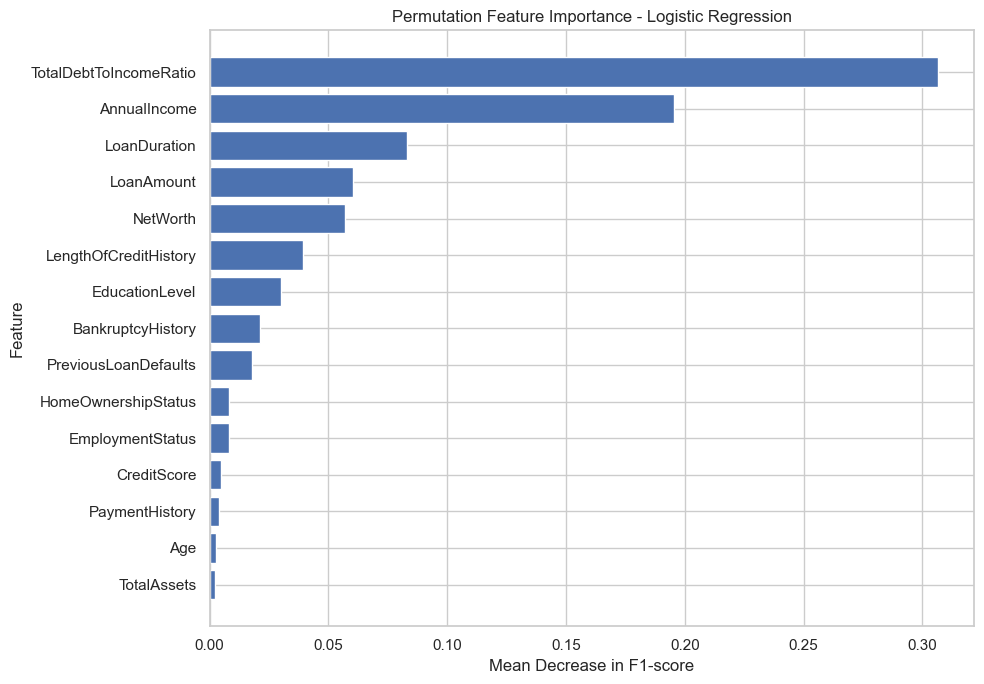

In [19]:

from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# Calculate permutation importance using the training data
perm_results = permutation_importance(
    best_model,
    X_train,
    y_train,
    scoring="f1",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

# Create importance table
permutation_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": perm_results.importances_mean,
    "Std": perm_results.importances_std
})

# Sort by importance
permutation_df = permutation_df.sort_values(
    "Importance",
    ascending=False
)

print("Top 15 Features by Permutation Importance:")
display(permutation_df.head(15).round(4))

# Plot top 15
top_perm = permutation_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(
    top_perm["Feature"],
    top_perm["Importance"]
)

plt.xlabel("Mean Decrease in F1-score")
plt.ylabel("Feature")
plt.title("Permutation Feature Importance - Logistic Regression")

plt.tight_layout()
plt.show()


### Permutation Feature Importance Analysis

Permutation importance was applied to the tuned Logistic Regression model to assess the contribution of individual features to classification performance.

The method measures the average reduction in F1-score when each feature is randomly shuffled while the remaining features are unchanged.

**Key Findings**

1. **Total Debt-to-Income Ratio** was the most influential feature, with a mean F1-score reduction of 0.3064. This indicates that the model relies heavily on information about applicants' debt obligations relative to income.

2. **Annual Income** ranked second, with an importance score of 0.1955, confirming its substantial contribution to predicted loan approval.

3. **Loan Duration** and **Loan Amount** recorded importance scores of 0.0832 and 0.0605, respectively, demonstrating the contribution of loan characteristics to classification performance.

4. **Net Worth** (0.0571) and **Length of Credit History** (0.0394) also contributed to the model's predictions.

5. **Education Level** (0.0299) and **Bankruptcy History** (0.0210) had smaller but measurable contributions.

**Comparison with Logistic Regression Coefficients**

Both methods identified Total Debt-to-Income Ratio and Annual Income as influential predictors.

The coefficient analysis showed the direction of each feature's association with predicted approval, while permutation importance measured how much the model's performance depended on each feature.

The two methods provide complementary explanations of the model's behaviour.

**Business Implications**

The results suggest that affordability measures, particularly debt-to-income ratio and annual income, are central to reproducing the simulated loan approval decisions.

A lending assessment framework could examine repayment capacity, existing debt obligations, requested loan amounts and credit history when reviewing applications.

These findings should not be used to establish automatic approval or rejection rules without validation using real repayment data.

**Limitations**

Permutation importance was calculated using the training dataset. Future assessments should examine stability using separate validation data.

Correlated predictors may share predictive information, which can affect their individual importance scores.

The findings describe a model trained on synthetic approval decisions and do not establish the causes of actual loan defaults.

### Question 10: Executive Summary, Recommendations and Future Improvements

#### 10.1 Executive Summary

**Project Objective**

This project developed and evaluated machine learning classification models to predict loan approval decisions using applicant financial information, credit history and loan characteristics.

The analysis followed the CRISP-DM framework, covering business understanding, data understanding, data preparation, modeling and evaluation.

**Dataset Overview**

The dataset contained 20,000 loan applications, of which 76.1% were rejected and 23.9% were approved.

The dataset was synthetically generated using predefined approval rules. Therefore, the project evaluates the prediction of simulated loan approval decisions rather than actual loan repayment or default outcomes.

**Model Development**

Five classification algorithms were evaluated:

- Logistic Regression
- Decision Tree
- Random Forest
- Gradient Boosting
- Extra Trees

Five-fold stratified cross-validation was used to compare the models.

Logistic Regression and Gradient Boosting were selected for hyperparameter tuning because they achieved the strongest baseline F1-scores.

RandomizedSearchCV was used to tune both models, with F1-score serving as the primary selection metric.

**Final Model Performance**

Tuned Logistic Regression was selected as the preferred model.

Its performance on the independent test dataset was:

| Metric | Result |
|---|---:|
| Accuracy | 93.35% |
| Precision | 87.58% |
| Recall | 84.10% |
| F1-score | 85.81% |
| ROC-AUC | 97.84% |

The model correctly classified 2,930 rejected applications and 804 approved applications.

It incorrectly predicted 114 rejected applications as approved and 152 approved applications as rejected.

These results indicate strong performance in reproducing simulated loan approval decisions.

#### 10.2 Key Findings

**1. Financial Affordability**

Total Debt-to-Income Ratio was the most influential predictor, with a permutation importance score of 0.3064.

Annual Income ranked second, with a score of 0.1955.

These findings suggest that affordability measures are central to the simulated approval decisions.

**2. Loan Characteristics**

Loan Duration and Loan Amount were among the most influential features, with permutation importance scores of 0.0832 and 0.0605, respectively.

Both had negative coefficients in the Logistic Regression model, indicating that larger loan amounts and longer durations were associated with lower predicted approval probabilities.

**3. Financial Position and Credit History**

Net Worth, Length of Credit History and Bankruptcy History contributed to model predictions.

Higher net worth and longer credit history were associated with higher predicted approval probabilities, while bankruptcy history was associated with lower approval probability.

**4. Differences Across Applicant Groups**

The segment analysis identified differences in classification error rates.

Self-employed applicants recorded a false rejection rate of 23.17%, compared with 14.93% among employed applicants.

Applicants aged 18–45 also recorded higher false rejection rates than applicants aged 46–60.

These differences require further investigation but do not independently establish unfair discrimination.

#### 10.3 Illustrative Business Cost Analysis

The assignment identifies two potential business costs:

- $50,000 for wrongly approving a bad loan.
- $8,000 for wrongly rejecting a creditworthy applicant.

Applying these assumptions to the selected model's classification errors produces the following illustrative calculation:

| Classification error | Cases | Assumed unit cost | Illustrative cost |
|---|---:|---:|---:|
| Rejected applications predicted as approved | 114 | $50,000 | $5,700,000 |
| Approved applications predicted as rejected | 152 | $8,000 | $1,216,000 |
| **Total** | **266** | | **$6,916,000** |

This calculation assumes, solely for illustration, that historical approval labels represent actual creditworthiness.

That assumption is not supported by the dataset. The data contains simulated approval outcomes rather than actual repayment or default information.

Therefore, the calculated amount is not an estimate of realized or expected financial losses. A valid financial risk assessment would require actual repayment outcomes and evidence-based cost assumptions.

#### 10.4 Business Recommendations

**1. Strengthen Affordability Assessments**

Loan assessments should consider applicants' debt obligations relative to income, repayment capacity and requested loan terms.

The strong influence of Total Debt-to-Income Ratio suggests that affordability measures deserve particular attention in further lending research.

**2. Use Machine Learning as Decision Support**

The model could be explored as a tool for identifying applications that require additional review.

It should not be used to make automatic lending decisions based solely on the current synthetic dataset.

**3. Review Performance Across Applicant Groups**

Further analysis should investigate differences in error rates across age groups, employment categories and education levels.

Particular attention should be given to self-employed applicants and groups with smaller sample sizes.

**4. Improve Data Quality**

Future data collection should prioritize complete and accurate applicant information, particularly financial and credit history variables.

Missing data patterns should be monitored to identify possible effects on model predictions.

**5. Validate Models Against Actual Repayment Outcomes**

Before practical deployment, future models should be trained and evaluated using real loan repayment and default data.

This would allow the lender to assess actual credit risk and estimate the financial consequences of incorrect decisions.

#### 10.5 Limitations

The project has several limitations:

1. **Synthetic Data:** The dataset was generated using programmed approval rules and may not represent actual lending behaviour.

2. **Target Variable:** LoanApproved represents simulated approval decisions rather than repayment or default outcomes.

3. **Potential Bias:** Differences in error rates across applicant groups require further investigation. The synthetic approval rules may themselves contain unequal treatment.

4. **Data Leakage:** RiskScore was excluded because the supplied generation script calculates it using LoanApproved.

5. **Model Interpretation:** Feature importance describes predictive relationships and does not establish causation.

6. **Generalizability:** Strong test performance on synthetic data does not guarantee comparable performance on real lending data.

#### 10.6 Potential Improvements

Future work should consider:

- Obtaining real loan repayment and default data.
- Assessing the effects of class imbalance and alternative classification thresholds.
- Comparing additional algorithms and model configurations.
- Conducting more detailed fairness assessments across applicant groups.
- Evaluating model calibration and the reliability of predicted probabilities.
- Testing performance on independent datasets collected over different periods.
- Establishing procedures for monitoring model performance and changes in data patterns.



### Classification Threshold and Business Cost Analysis

The default classification threshold of 0.50 may not reflect the different financial consequences of incorrect loan approval decisions.

The assignment specifies a cost of $50,000 for wrongly approving a bad loan and $8,000 for wrongly rejecting a creditworthy applicant.

A threshold sensitivity analysis will examine how different probability thresholds affect false approvals, false rejections and illustrative classification costs.

Out-of-fold predictions from the training dataset will be used to compare thresholds without selecting a threshold based on the test dataset.

Since the dataset contains simulated approval outcomes rather than actual repayment or default outcomes, the financial calculations will be treated as hypothetical scenarios rather than estimates of real credit losses.

Classification Threshold Comparison:


,Threshold,False Approvals,False Rejections,F1-score,Illustrative Cost
0,0.20,1258,204,0.831993,64532000
1,0.25,1065,269,0.842018,55402000
2,0.30,927,339,0.846285,49062000
3,0.35,797,404,0.850640,43082000
4,0.40,679,474,0.853177,37742000
5,0.45,582,551,0.852455,33508000
6,0.50,501,624,0.850498,30042000
7,0.55,425,703,0.846947,26874000
8,0.60,349,804,0.839705,23882000
9,0.65,288,898,0.831486,21584000



Lowest Illustrative-Cost Threshold:


,Threshold,False Approvals,False Rejections,F1-score,Illustrative Cost
13,0.85,90.0,1461.0,0.752907,16188000.0


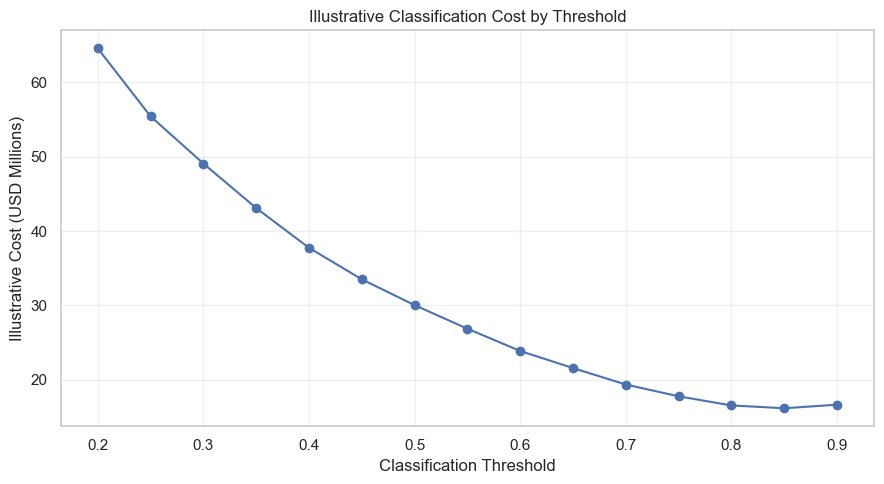

In [20]:

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, f1_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Generate out-of-fold probabilities on training data
cv_probabilities = cross_val_predict(
    lr_search.best_estimator_,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Define thresholds and illustrative error costs
thresholds = np.arange(0.20, 0.91, 0.05)

false_approval_cost = 50000
false_rejection_cost = 8000

threshold_results = []

for threshold in thresholds:
    predictions = (cv_probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_train, predictions, labels=[0, 1]
    ).ravel()

    illustrative_cost = (
        fp * false_approval_cost
        + fn * false_rejection_cost
    )

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "False Approvals": fp,
        "False Rejections": fn,
        "F1-score": f1_score(y_train, predictions),
        "Illustrative Cost": illustrative_cost
    })

threshold_df = pd.DataFrame(threshold_results)

print("Classification Threshold Comparison:")
display(threshold_df)

# Identify the lowest illustrative-cost threshold
best_threshold_row = threshold_df.loc[
    threshold_df["Illustrative Cost"].idxmin()
]

print("\nLowest Illustrative-Cost Threshold:")
display(best_threshold_row.to_frame().T)

# Visualize threshold impact
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Illustrative Cost"] / 1_000_000,
    marker="o"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Illustrative Cost (USD Millions)")
plt.title("Illustrative Classification Cost by Threshold")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Classification Threshold Analysis: Results and Interpretation

A classification threshold sensitivity analysis was conducted using out-of-fold predictions from the training dataset.

Thresholds ranging from 0.20 to 0.90 were evaluated to examine their effects on false approvals, false rejections, F1-score and illustrative business costs.

**Key Findings**

1. The highest F1-score of 0.8532 was achieved at a threshold of 0.40. This threshold produced 679 false approvals and 474 false rejections.

2. At the default threshold of 0.50, the model produced 501 false approvals and 624 false rejections, with an F1-score of 0.8505 and an illustrative cost of $30.04 million.

3. The lowest illustrative cost of $16.19 million occurred at a threshold of 0.85. This threshold produced 90 false approvals and 1,461 false rejections, with an F1-score of 0.7529.

4. Increasing the classification threshold reduced false approvals but increased false rejections.

**Business Interpretation**

The analysis demonstrates that the threshold with the highest F1-score does not necessarily produce the lowest cost under asymmetric error assumptions.

Because the assumed cost of an incorrect approval is substantially higher than that of an incorrect rejection, higher thresholds produced lower illustrative costs within the tested range.

The results highlight the need to consider business consequences alongside predictive performance when selecting classification thresholds.

**Limitations**

The financial calculations are hypothetical because the dataset contains simulated approval decisions rather than actual loan repayment outcomes.

The threshold of 0.85 minimizes the assumed cost only among the tested thresholds and should not be interpreted as an appropriate lending threshold for real-world use.

A valid cost-based lending model would require actual repayment outcomes, calibrated probabilities and evidence-based estimates of financial losses.

**Conclusion**

The threshold analysis demonstrates the trade-off between statistical performance and assumed business costs.

The default threshold of 0.50 remains the threshold used for the reported final test evaluation. The threshold sensitivity analysis provides a separate illustration of how different decision thresholds affect model predictions.

#### 10.7 Final Conclusion

The project successfully developed and compared five classification models for predicting simulated loan approval decisions.

Tuned Logistic Regression achieved the strongest overall performance, recording an F1-score of 85.81% and ROC-AUC of 97.84% on the test dataset.

Feature importance analysis identified Total Debt-to-Income Ratio and Annual Income as the most influential predictors, followed by Loan Duration, Loan Amount and Net Worth.

Although the model demonstrated strong predictive performance, its results are limited by the synthetic nature of the dataset and the absence of actual repayment outcomes.

The findings provide a foundation for further research into data-driven lending assessments. Practical deployment would require real-world validation, fairness assessment and evaluation against actual credit risk outcomes.